# Phase 1: Who is treated, and who are they compared to?

**ECO 3630 · AI data centers and their host towns**

This notebook turns the hand-built site panel into the two things every later analysis needs:

1. **Treatment tables:** which ZIPs and counties got an AI data center, and in which month.
2. **Control candidates:** places in the same states that are far enough from every data center to serve as a fair comparison.

All the logic lives in `src/` (tested in `tests/`). This notebook just runs it and shows the results. To rebuild the output files from the command line: `python scripts/build_treatment.py`.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/your-github-username/eco3630-ai-datacenters/blob/main/notebooks/01_treatment_and_controls.ipynb)

In [1]:
# Setup: the same cell works in VS Code / Jupyter and in Google Colab.
import os, subprocess, sys
from pathlib import Path

REPO_URL = "https://github.com/your-github-username/eco3630-ai-datacenters.git"

if "google.colab" in sys.modules:                      # Colab: get the repo first
    target = Path("/content/eco3630-ai-datacenters")
    if not target.exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, str(target)], check=True)
    os.chdir(target)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)

# find the project folder (the one with src/ in it) and work from there
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))


def run(script, *args):
    """Run scripts/<script> with this notebook's Python and show its output as it goes."""
    env = {**os.environ, "PYTHONIOENCODING": "utf-8"}     # Windows-safe printing
    proc = subprocess.Popen([sys.executable, "-u", f"scripts/{script}", *args], env=env,
                            stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                            text=True, encoding="utf-8", errors="replace")
    for line in proc.stdout:
        print(line, end="")
    if proc.wait():
        raise RuntimeError(f"scripts/{script} stopped with an error (see above)")


print("Working in the project folder:", ROOT.name)

Working in the project folder: eco3630-ai-datacenters


In [2]:
import pandas as pd
from IPython.display import display

from src.io_utils import load_site_panel, sample
from src.treatment import build_treated, treated_sites, treatment_summary
from src.geo import candidate_zips, candidate_counties, pool_summary
from src.figures_phase1 import site_map, treatment_timeline
pd.set_option("display.max_colwidth", 60)

## 1. The site panel

80 data center sites, each checked against a primary source. The panel's validator runs automatically on load; a typo in the CSV stops the code here with a clear message rather than breaking a join later.

In [3]:
panel = load_site_panel()
pd.crosstab(panel.ai_tier, panel.status, margins=True, margins_name="Total")

status,Announced/Permitted,Operating,Proposed,Under construction,Total
ai_tier,,,,,
AI-purpose-built,1,9,1,5,16
Colocation-AI-tenancy-unconfirmed,6,2,1,4,13
Hyperscale-AI-documented,8,29,0,9,46
Unclear,4,0,1,0,5
Total,19,40,3,18,80


**Two samples are built in.** The strict sample (17 sites) is the headline: operating, with a dated AI start, and either built for AI or with evidence that *this* site runs AI. The broad sample (37) adds hyperscale sites whose AI evidence is company-wide, as a robustness check.

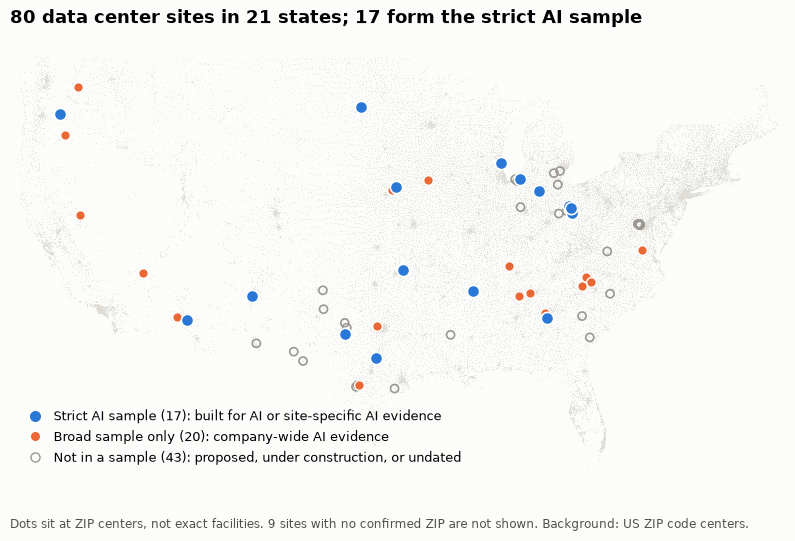

In [4]:
fig = site_map(panel)

## 2. When did AI arrive?

Each strict site has a **treatment month** (when AI operations began) and, where sources state it, an **announcement month**. Housing markets often react at announcement, so we test both dates.

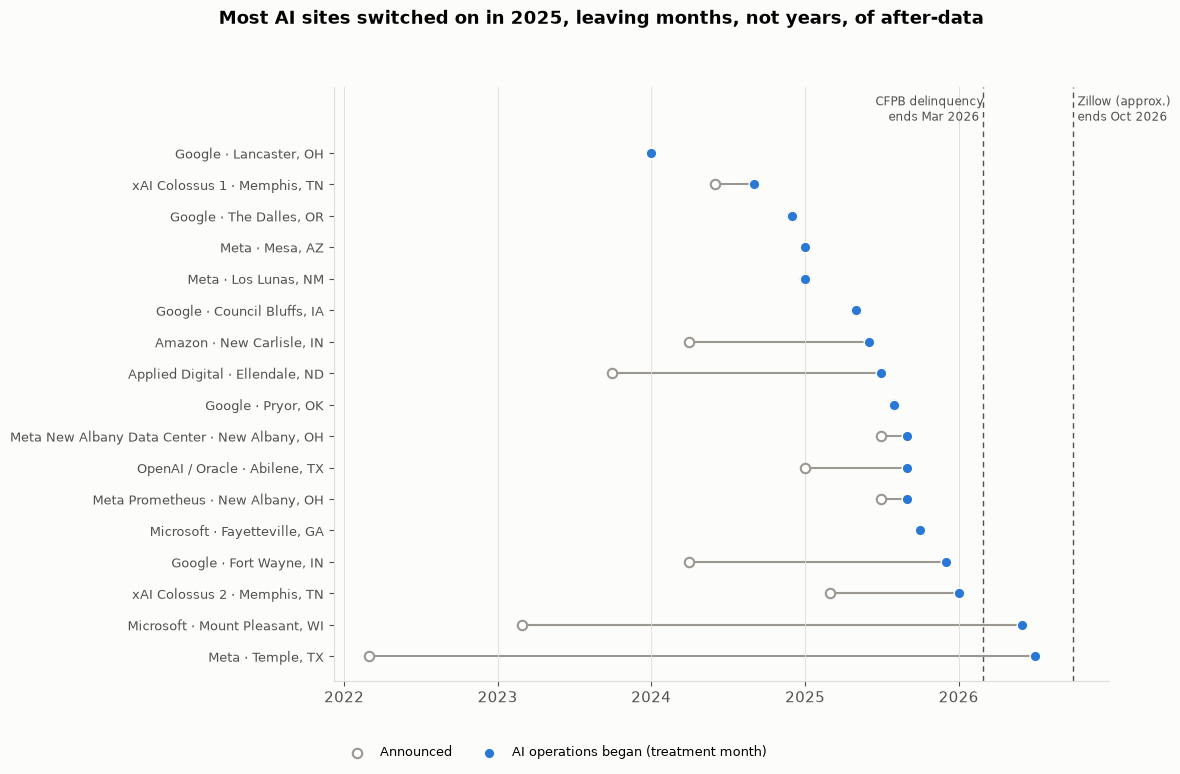

In [5]:
strict_sites = treated_sites(panel, "strict")
fig = treatment_timeline(strict_sites, {"Zillow (approx.)": "2026-10-01",
                                        "CFPB delinquency": "2026-03-01"})

**What this means for the analysis:** 11 of the 17 sites started in 2025, giving them roughly 10 to 21 months of housing data after treatment, and fewer months of delinquency data. Temple and Mount Pleasant started in mid-2026, so they contribute mostly to announcement-effect tests. We report results as early evidence, not final verdicts.

## 3. Treatment tables

One row per treated place. Two rules keep these honest:
- **ZIP level uses only ZIPs from a facility's actual address.** A town-level ZIP can sit miles from the building.
- **Sites sharing a place collapse into one row**, dated by the earlier site. xAI Colossus 1 and 2 share ZIP 38109, so 17 sites become 15 treated ZIPs.

In [6]:
treatment_summary(panel)

,sample,level,sites,treated_places,states,first_treatment,last_treatment
0,strict,zip,17,15,11,2024-01,2026-07
1,strict,county,17,15,12,2024-01,2026-07
2,broad,zip,37,32,17,2007-07,2026-07
3,broad,county,37,31,18,2007-07,2026-07


In [7]:
build_treated(panel, "strict", "zip")[["geo_id", "state", "treat_month", "announce_month",
                                          "n_sites", "site_names"]]

,geo_id,state,treat_month,announce_month,n_sites,site_names
0,85212,AZ,2025-01-01,NaT,1,Mesa Data Center
1,30214,GA,2025-10-01,NaT,1,Microsoft Fairwater Atlanta (QTS Fayetteville campus)
2,51501,IA,2025-05-01,2025-05-01,1,Google Council Bluffs Data Center
3,46552,IN,2025-06-01,2024-04-01,1,Northern Indiana Campus (Project Rainier)
4,46816,IN,2025-12-01,2024-04-01,1,Fort Wayne Data Center
5,58436,ND,2025-07-01,2023-10-01,1,"Applied Digital Polaris Forge 1 (Ellendale, ND)"
6,43054,OH,2025-09-01,2025-07-01,1,Meta New Albany Data Center (incl. Prometheus AI cluster)
7,43062,OH,2025-09-01,2025-07-01,1,"Meta Prometheus (New Albany, OH)"
8,43130,OH,2024-01-01,NaT,1,Lancaster Data Center (Google)
9,74361,OK,2025-08-01,2025-08-01,1,Google Mayes County (Pryor) Data Center


## 4. Who can be a control?

A control ZIP must be **in the same state** as a treated ZIP, **at least 15 miles from every site in the panel** (including non-AI and unfinished ones), and **outside any county that hosts a site**. The 15-mile buffer follows research finding that hyperscale price effects fade beyond about 9 miles.

In [8]:
treated_zips = build_treated(panel, "broad", "zip")
cand = candidate_zips(panel, treated_zips)
print(f"{len(cand):,} candidate control ZIPs across {cand.state.nunique()} states")
pool_summary(build_treated(panel, "strict", "zip"), cand)

10,273 candidate control ZIPs across 17 states


,state,treated,candidates,candidates_per_treated
0,AZ,1,128,128
1,GA,1,609,609
2,IA,1,842,842
3,IN,2,627,314
4,ND,1,374,374
5,OH,3,903,301
6,OK,1,582,582
7,OR,1,382,382
8,TN,1,553,553
9,TX,2,1491,746


Every treated state has well over the 10 controls we need. Arizona has the fewest because Maricopa County, home to most of the state's ZIPs, hosts several sites and is excluded.

## 5. Next step: matching

From each state's pool, `scripts/match_controls.py` picks the **10 ZIPs whose home values looked most like the treated ZIP's** over the 36 months before treatment, on both price level and growth rate. It needs the Zillow data, so it runs right after the Zillow pull (Phase 3).

It was tested on simulated data: all 15 strict ZIPs matched, with treated and control growth within 0.1 percentage point per year. With real data, any ZIP lacking enough history is listed with the reason, not silently dropped.